## Create Agent to give weather of a city


In [1]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

In [2]:
WEATHER_API_KEY= os.environ['WEATHER_API_KEY'] 

In [4]:
from langchain_core.tools import tool
import requests
import json

In [6]:
@tool
def get_weather(query: str) -> list:
    """Search weatherapi to get the current weather of the queried location."""
    print('Calling weather tool')
    base_url = "http://api.weatherapi.com/v1/current.json"
    complete_url = f"{base_url}?key={WEATHER_API_KEY}&q={query}"

    response = requests.get(complete_url)
    data = response.json()
    if data.get("location"):
        return data
    else:
        return "Weather Data Not Found"

In [7]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o", temperature=0)

tools = [get_weather]

llm_with_tools = llm.bind_tools(tools)

In [8]:
from langchain_core.messages import SystemMessage
from langchain_core.messages import HumanMessage
from langgraph.prebuilt import create_react_agent

In [9]:
sys_prompt ="""you are an agent designed to give the weather update for given
location 
You have access to tools for interacting with the weather api.
Only use the below tools. Only use the information returned by the below tools to construct your final answer.
Weather Tool:
   Use get_weather for weather-related queries.
Rules:
 - Use tool results to formulate the final answer.
"""

SYS_PROMPT = SystemMessage(content=sys_prompt)

In [10]:
weather_info_agent = create_react_agent(model=llm,
                                    tools=tools,
                                    prompt=SYS_PROMPT)

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_83370/4060273624.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  weather_info_agent = create_react_agent(model=llm,


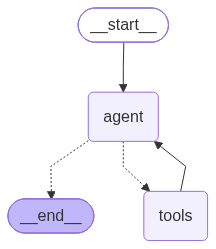

In [11]:
weather_info_agent

In [12]:
from IPython.display import display, Markdown
for event in weather_info_agent.stream(
    {"messages": [HumanMessage(content="What is the weather of city Bangalore today ?")]},
    stream_mode='values' #returns full agent state with all messages including updates
):
    event["messages"][-1].pretty_print()

print('\n\nFinal Response:\n')
display(Markdown(event["messages"][-1].content))

================================ Human Message =================================

What is the weather of city Bangalore today ?
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_9pnuZeMP6w4A86kMI7cvCTre)
 Call ID: call_9pnuZeMP6w4A86kMI7cvCTre
  Args:
    query: Bangalore
Calling weather tool
================================= Tool Message =================================
Name: get_weather

{"location": {"name": "Bangalore", "region": "Karnataka", "country": "India", "lat": 12.9833, "lon": 77.5833, "tz_id": "Asia/Kolkata", "localtime_epoch": 1793168125, "localtime": "2026-10-28 11:45"}, "current": {"last_updated_epoch": 1793167200, "last_updated": "2026-10-28 11:30", "temp_c": 26.4, "temp_f": 79.6, "is_day": 1, "condition": {"text": "Overcast", "icon": "//cdn.weatherapi.com/weather/64x64/day/122.png", "code": 1009}, "wind_mph": 12.5, "wind_kph": 20.2, "wind_degree": 291, "wind_dir": "WNW", "pressure_mb": 1010.0, "pressure_i

The current weather in Bangalore, India, is overcast with a temperature of 26.4°C (79.6°F). The wind is blowing from the west-northwest at 20.2 kph (12.5 mph), and the humidity level is at 43%. There is no precipitation at the moment, and the visibility is 10 kilometers (6 miles). The UV index is 9, indicating a high level of UV radiation.

In [13]:
# Invoke the agent with the input message
response = weather_info_agent.invoke(
    {"messages": [HumanMessage(content="What is the weather of city Bangalore today ?")]}
)

# Display the final response
print('\n\nFinal Response:\n')
display(Markdown(response["messages"][-1].content))

Calling weather tool


Final Response:



The current weather in Bangalore, India, is overcast with a temperature of 26.4°C (79.6°F). The wind is blowing from the west-northwest at 20.2 kph (12.5 mph). The humidity level is at 43%, and there is no precipitation at the moment. The visibility is 10 kilometers (6 miles), and the UV index is 9, indicating a high level of UV radiation. The chance of rain is low at 10%.